In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#create our superhero data set

In [3]:
data = {
  "Hero" :[
  "Iron man",
  "Spider-Man",
  "Thor",
  "Hulk",
  "Captian America",
  "Docter Strange",
  "Black Panther",
  "Captian Marvel",
  "Hawkeye",
  "Docter Doom"
  ],
  "Intelligence":[95,85,75,60,75,95,90,80,75,100],
  "Strength":[70,65,100,100,60,70,65,95,45,85],
  "Speed":[75,80,85,55,65,70,70,95,60,65]

}

# convert the data into a table
df = pd.DataFrame(data)
#Display the dataset
print(df)

              Hero  Intelligence  Strength  Speed
0         Iron man            95        70     75
1       Spider-Man            85        65     80
2             Thor            75       100     85
3             Hulk            60       100     55
4  Captian America            75        60     65
5   Docter Strange            95        70     70
6    Black Panther            90        65     70
7   Captian Marvel            80        95     95
8          Hawkeye            75        45     60
9      Docter Doom           100        85     65


In [4]:
# find the superhero with the highest strength
strongest_hero = df.loc[df["Strength"].idxmax()]

print("Strongest superhero:", strongest_hero["Hero"])
print("Strength score:", strongest_hero["Strength"])

Strongest superhero: Thor
Strength score: 100


In [5]:
average_intelligence = df["Intelligence"].mean()
print("Average intelligence score", average_intelligence)

Average intelligence score 83.0


In [6]:
selected_heroes = df[df["Hero"].isin(
    ["Iron man","Spider-Man","Thor"]
)]
print(selected_heroes)

         Hero  Intelligence  Strength  Speed
0    Iron man            95        70     75
1  Spider-Man            85        65     80
2        Thor            75       100     85


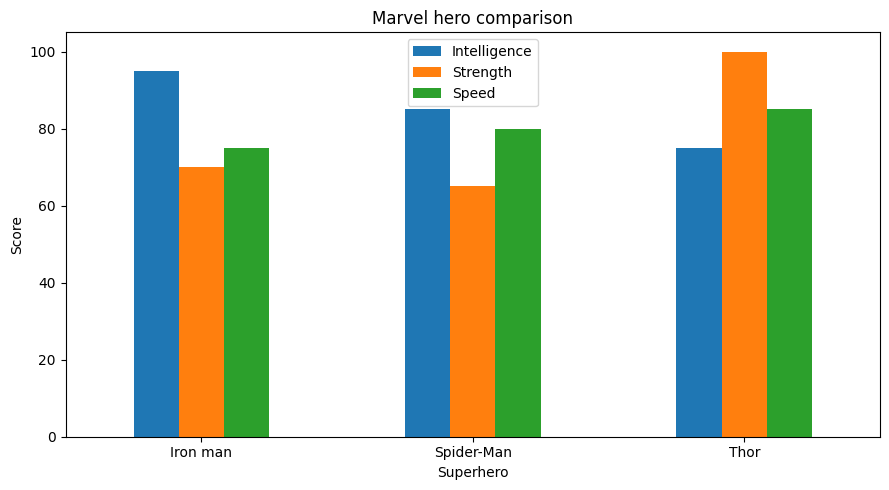

In [7]:
import matplotlib.pyplot as plt

selected_heroes.plot(
    x="Hero",
    y=["Intelligence","Strength","Speed"],
    kind="bar",
    figsize=(9,5)
)
plt.title("Marvel hero comparison")
plt.xlabel("Superhero")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
print("first five rows:")
display(df.head())

first five rows:


,Hero,Intelligence,Strength,Speed
0,Iron man,95,70,75
1,Spider-Man,85,65,80
2,Thor,75,100,85
3,Hulk,60,100,55
4,Captian America,75,60,65


In [9]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Hero', 'Intelligence', 'Strength', 'Speed']


In [10]:
print("dataset size (rows,colums):")
print(df.shape)

dataset size (rows,colums):
(10, 4)


In [11]:
print("Data types and non missing values:")
df.info()

Data types and non missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Hero          10 non-null     object
 1   Intelligence  10 non-null     int64 
 2   Strength      10 non-null     int64 
 3   Speed         10 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 452.0+ bytes


In [12]:
HERO_COL = "Hero"
STRENGTH_COL = "Strength"
INTELLIGENCE_COL = "Intelligence"

print("Available columns:", df.columns.tolist())
print("Hero column exists:", HERO_COL in df.columns)
print("Strength column exists:", STRENGTH_COL in df.columns)
print("Intelligence column exists:", INTELLIGENCE_COL in df.columns)

Available columns: ['Hero', 'Intelligence', 'Strength', 'Speed']
Hero column exists: True
Strength column exists: True
Intelligence column exists: True


In [13]:
print("Missing values per column:")
display(df.isna().sum().sort_values(ascending=False))

Missing values per column:


,0
Hero,0
Intelligence,0
Strength,0
Speed,0


In [14]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Data types:")
display(df.dtypes)

Exact duplicate rows: 0
Data types:


,0
Hero,object
Intelligence,int64
Strength,int64
Speed,int64


In [15]:
marvel = df.copy()
marvel = marvel.drop_duplicates()

In [16]:
print("original row count:",len(df))
print("Working-copy row count:", len(marvel))

original row count: 10
Working-copy row count: 10


In [17]:
if STRENGTH_COL in marvel.columns:
  marvel[STRENGTH_COL] = pd.to_numeric(
      marvel[STRENGTH_COL], errors="coerce"
  )

if INTELLIGENCE_COL in marvel.columns:
  marvel[INTELLIGENCE_COL] = pd.to_numeric(
      marvel[INTELLIGENCE_COL], errors="coerce"
  )

display(marvel.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hero,10,10,Iron man,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Intelligence,10.0,NaN,NaN,NaN,83.0,12.292726,60.0,75.0,82.5,93.75,100.0
Strength,10.0,NaN,NaN,NaN,75.5,18.626445,45.0,65.0,70.0,92.5,100.0
Speed,10.0,NaN,NaN,NaN,72.0,12.064641,55.0,65.0,70.0,78.75,95.0


In [18]:
# find the highest recorded strength score
if STRENGTH_COL in marvel.columns:
  strength_data = marvel.dropna(subset=[STRENGTH_COL])
  if not strength_data.empty:
    top_hero = strength_data.loc[
        strength_data[STRENGTH_COL].idxmax()
    ]
    if HERO_COL in marvel.columns:
      print("highest recorded score:", top_hero[HERO_COL])
    else:
      print(top_hero)
      print("Score:", top_hero[STRENGTH_COL])
  else:
    print("No usable numeric scores found.")
else:
  print("Map STRENGTH_COL to real numeric column first.")

highest recorded score: Thor


In [19]:
#calculate average intelligence

INTELLIGENCE_COL = "Intelligence"

if INTELLIGENCE_COL in marvel.columns:
  scores = pd.to_numeric(
      marvel[INTELLIGENCE_COL], errors="coerce"
  )
  print("Average intelligence:", round(scores.mean(), 2))
  print("Non-missing scores counted:", scores.count())
else:
  print("No intelligence column; skip this analysis.")

Average intelligence: 83.0
Non-missing scores counted: 10


In [20]:
#compare iron man , spider man , and thor
if HERO_COL in marvel.columns:
  wanted = ["iron man", "spider-man", "thor"]
  names = marvel[HERO_COL].astype(str).str.strip().str.casefold()
  comparison = marvel[names.isin(wanted)].copy()

  show_cols = [HERO_COL]
  for col in [STRENGTH_COL, INTELLIGENCE_COL]:
    if col in comparison.columns and col not in show_cols:
      show_cols.append(col)

  if not comparison.empty:
    display(comparison[show_cols])
  else:
    print("No exact matches. Check character-name spelling.")
else:
  print("Set HERO_COL to the correct name column first.")

,Hero,Strength,Intelligence
0,Iron man,70,95
1,Spider-Man,65,85
2,Thor,100,75


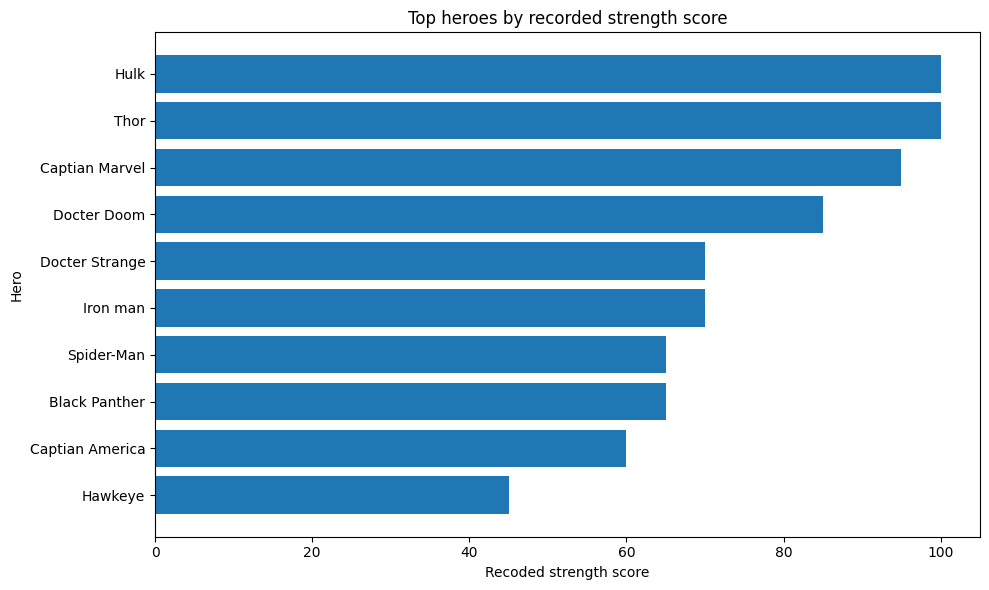

In [21]:
#top  hero horizontal bar

if HERO_COL in marvel.columns and STRENGTH_COL in marvel . columns:
  chart_data = marvel.dropna(subset=[STRENGTH_COL]).nlargest(
      10, STRENGTH_COL
    )
  if not chart_data.empty:
    plt.figure(figsize=(10,6))
    plt.barh(chart_data[HERO_COL].astype(str),chart_data[STRENGTH_COL])
    plt.xlabel("Recoded strength score")
    plt.ylabel("Hero")
    plt.title("Top heroes by recorded strength score")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

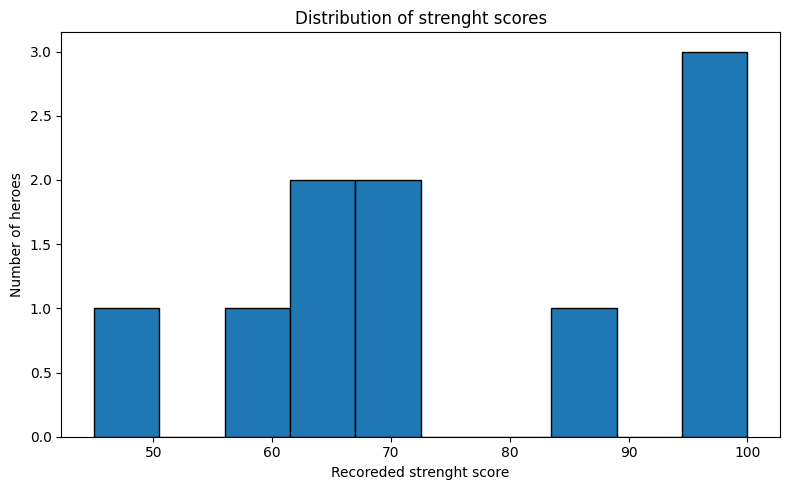

In [22]:
#show the score distribtion
if STRENGTH_COL in marvel . columns:
  values = marvel [STRENGTH_COL].dropna()
  if not values.empty:
    plt.figure(figsize=(8,5))
    plt.hist(values, bins=10,edgecolor = "black")
    plt.xlabel("Recoreded strenght score")
    plt.ylabel("Number of heroes")
    plt.title("Distribution of strenght scores")
    plt.tight_layout()
    plt.show()

,Intelligence,Strength,Speed
Intelligence,1.00,-0.25,0.20
Strength,-0.25,1.00,0.34
Speed,0.20,0.34,1.00


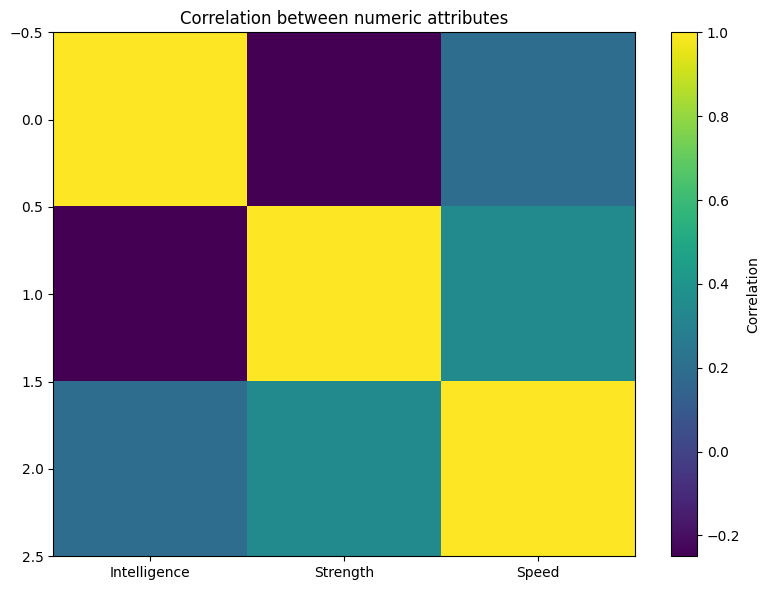

In [23]:
#explore relationships between numeric columns

numeric_data = marvel.select_dtypes(include="number")
if numeric_data.shape[1] >= 2:
  correlation = numeric_data.corr(numeric_only=True)
  display(correlation.round(2))
  plt.figure(figsize=(8,6))
  plt.imshow(correlation,aspect="auto")
  plt.colorbar(label = "Correlation")
  plt.xticks(range(len(correlation.index)),correlation.index)
  plt.title("Correlation between numeric attributes")
  plt.tight_layout()
  plt.show()

In [24]:
#generate evidence -based finding
print("MARVEL DATA ANALYSIS - KEY FINDINGS")
print("-----------------------------------")
print("Records in working copy:", len(marvel))
print("Columns available:",len(marvel.columns))

if  STRENGTH_COL in marvel.columns:
  valid = marvel.dropna(subset=[STRENGTH_COL])
  if not valid.empty:
    best = valid.loc[valid[STRENGTH_COL].idxmax()]
    name = best[HERO_COL] if HERO_COL in marvel . columns else "Top row"
    print(f"highest recorded {STRENGTH_COL}: {name}({best[STRENGTH_COL]}).")

if INTELLIGENCE_COL in marvel.columns:
  avg = pd.to_numeric(marvel[INTELLIGENCE_COL],errors="coerce").mean()
  print(f"Average{INTELLIGENCE_COL}:{avg:2f}.")

MARVEL DATA ANALYSIS - KEY FINDINGS
-----------------------------------
Records in working copy: 10
Columns available: 4
highest recorded Strength: Thor(100).
AverageIntelligence:83.000000.


In [25]:
#exports data and summary tables
import os
os.makedirs("marvel_project_outputs", exist_ok=True)
marvel.to_csv("marvel_project_outputs/marvel_cleaned.csv", index=False)
marvel.describe(include="all").T.to_csv(
    "marvel_project_outputs/summary_statistics.csv"
)
print("Saved cleaned data and summary statistics.")

Saved cleaned data and summary statistics.
